# PROYECTO FINAL - ANÁLISIS DE SENTIMIENTOS, AFECTO Y CONNOTACIÓN

Para realizar tu proyecto final, escoge un corpus en inglés o español para hacer una de las tareas: o análisis de sentimiento o detección de emociones. Dichos corpus deben ser distintos de los utilizados en los cuadernos de clase o de las tareas evaluables, es decir, distintos de InterTASS, del corpus de las reseñas de Amazon y del corpus multietiqueta de emociones SemEval 2018.

El objetivo será comparar los resultados de los modelos desarrollados con los diversos enfoques vistos en clase.

Se espera un análisis cuantitativo de métricas y un análisis cualitativo crítico (de fallos y aciertos por cada modelo) que dé cuenta del rendimiento de cada modelo, apoyándote en la teoría para tus explicaciones.

Por cada modelo, añade a tu dataframe una columna con las predicciones correspondientes. Por último, discute la calidad del corpus etiquetado en función de los resultados obtenidos con los diversos modelos.


**Aprendizaje transferido-Análisis de sentimiento.**
TAREA: Para análisis de sentimiento, construir un modelo de aprendizaje transferido con un transformador y diversos hiperparámetros. Quédate con el mejor modelo, es decir, aquel que obtenga los mejores resultados en el conjunto de evaluación. Genera pérdidas por predicción y ordenar dataframe en función de las pérdidas para análisis de predicciones. Probar LIME con algunas instancias por cada categoría.

# ELECCIÓN DE TIPO DE ANÁLISIS Y DEL CORPUS

Para la realización de este proyecto, elijo el **análisis de sentimiento**, ya que dispongo del lexicón de SentiWordNet completamente traducido al español y querría aprovecharlo para la parte del proyecto que lo requiere.

Una vez tomada esta decisión, entre los corpus propuestos en el tema 1 y otros que he consultado, finalmente opto por trabajar con el **corpus "Andalusian Hotels’ Reviews"** disponible en kaggle.com/datasets/chizhikchi/andalusian-hotels-reviews-unbalanced

Son reseñas de hoteles de Andalucía, recogidas directamente en español. La creadora del corpus es Mariia Chizhikova, ingeniera de PLN en la Universidad de Jaén.

Las reseñas se clasifican según la etiqueta label en positivas (1), negativas (0) o neutras (3).

El corpus está disponible en dos versiones:

*   Reducida y equilibrada: Con 7.615 reseñas (Balanced_AHR.csv)
*   Completa: con 18.172 reseñas (Big_AHR.csv)

Respecto a esta última versión, 1816 del total de reseñas se han obtenido del COAH corpus (Molina-González, M. D., Martínez-Cámara, E., Martín-Valdivia, M. T., Ureña-López, L. A. (2014). Cross-domain sentiment analysis using spanish opinionated words. Natural Language Processing and Information Systems, Lecture Notes in Computer Science, vol. 8455, pp. 214-219. Springer International Publishing. DOI: 10.1007/978-3-319-07983-7_28).

Por su documentación, tamaño y etiquetado, me parece un corpus acertado para realizar este proyecto.

Continuamos con la cuarta y última parte:

# Aprendizaje transferido-Análisis de sentimiento.

**TAREA:**
Para análisis de sentimiento, construir un modelo de aprendizaje transferido con un transformador y diversos hiperparámetros. Quédate con el mejor modelo, es decir, aquel que obtenga los mejores resultados en el conjunto de evaluación. Genera pérdidas por predicción y ordenar dataframe en función de las pérdidas para análisis de predicciones. Probar LIME con algunas instancias por cada categoría.

Para este ejercicio, tomaremos como base el cuaderno de la tarea evaluable correspondiente al tema de aprendizaje transferido, y probaremos algunos de los hiperparámetros para ver si mejoran los resultados. Concretamente:

-         Número de épocas: 3 y 5
-         Learning rate: 2e-5 y 5e-5
-         Weight decay: 0.01


Comenzamos con la carga del dataset y las tareas de preprocesamiento y preparación de datos de las que ya disponíamos en el cuaderno del tema 5.

# Análisis, preprocesamiento y preparación de los datos

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Ruta al CSV
csv_path = '/content/drive/MyDrive/0.Apuntes PLN/Big_AHR.csv'
df = pd.read_csv(csv_path)
df.head()

,Unnamed: 0,title,rating,review_text,location,hotel,label
0,0,Excelente y personal amable,5,Un hotel muy bueno. El personal fue muy amabl...,Seville_Province_of_Seville_Andalucia,H10_Casa_de_la_Plata,1
1,1,Céntrico,4,"Muy buen hotel al nivel de lo esperado, habita...",Seville_Province_of_Seville_Andalucia,H10_Casa_de_la_Plata,1
2,2,Hotel excepcional,5,Magnífico hotel. La verdad es que todo perfect...,Seville_Province_of_Seville_Andalucia,H10_Casa_de_la_Plata,1
3,3,WOW!!,5,"Hotel hermoso, buen diseño, original, limpio. ...",Seville_Province_of_Seville_Andalucia,H10_Casa_de_la_Plata,1
4,4,Magnifico,5,Magnífica ubicación en pleno centro de Sevilla...,Seville_Province_of_Seville_Andalucia,H10_Casa_de_la_Plata,1


### Reproducibilidad

A continuación, preparamos el entorno para garantizar la reproducibilidad de nuestros experimentos. De este modo, todos los pasos que involucren aleatoriedad (barajado de datos, inicialización de pesos, etc.) se ejecutarán de manera idéntica cada vez, facilitando la comparación justa entre distintas configuraciones.

In [ ]:
import random, numpy as np, tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)



Mapeamos las etiquetas de polaridad originales del dataset (1, 0 y 3), las renombramos en POS, NEG y NEU respectivamente para facilitar la interpretación de los datos y las incluiremos bajo la etiqueta gold_label, ya que servirá como referencia para comparar el etiquetado original con las predicciones del modelo.

In [ ]:
# Mapeamos las etiquetas de polaridad originales del dataset y las renombramos para facilitar la interpretación de los datos

mapping = {1: 'POS', 0: 'NEG', 3: 'NEU'}
df['gold_label'] = df['label'].map(mapping)

# Verificamos las categorías que tenemos actualmente
print(df['gold_label'].value_counts())


gold_label
POS    13227
NEG     2671
NEU     2274
Name: count, dtype: int64


###Concatenar title + review text

Concatenaremos los textos de title y de la reseña. El título a menudo es un resumen del sentimiento de la reseña y aporta más información al modelo para detectar dicho sentimiento, por lo que puede ser útil para obtener mejores resultados.


In [ ]:
# Unimos el título y el cuerpo de la reseña en text_full
df['text_full'] = df['title'].fillna('') + '. ' + df['review_text']

# Verificamos la concatenación
print(df[['title','review_text','text_full']].head(3))

                         title  \
0  Excelente y personal amable   
1                     Céntrico   
2            Hotel excepcional   

                                         review_text  \
0  Un hotel muy bueno.  El personal fue muy amabl...   
1  Muy buen hotel al nivel de lo esperado, habita...   
2  Magnífico hotel. La verdad es que todo perfect...   

                                           text_full  
0  Excelente y personal amable. Un hotel muy buen...  
1  Céntrico. Muy buen hotel al nivel de lo espera...  
2  Hotel excepcional. Magnífico hotel. La verdad ...  


### División del corpus en conjuntos de entrenamiento, validación y prueba

Nuestro corpus no tiene una división explícita entre datos de entrenamiento, validación y prueba. Por ello, es necesario realizar esta partición.

A continuación, dividiremos el conjunto en:
80% para entrenamiento,
10% para validación (dev),
10% para prueba (test).

Añadiremos una columna de split para identificar a qué conjunto pertenece cada reseña.

Se emplea muestreo estratificado para que en cada subconjunto se mantenga la proporción original de clases (positiva, negativa y neutra).

In [ ]:
from sklearn.model_selection import train_test_split

# Crear splits
train_idx, temp_idx = train_test_split(
    df.index,
    test_size=0.2,
    random_state=SEED,
    stratify=df['gold_label']
)
dev_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    random_state=SEED,
    stratify=df.loc[temp_idx, 'gold_label']
)
df['split'] = 'unspecified'
df.loc[train_idx, 'split'] = 'train'
df.loc[dev_idx,   'split'] = 'dev'
df.loc[test_idx,  'split'] = 'test'

print(df['split'].value_counts(normalize=True))

# Crear subconjuntos barajados
columnas = ['text_full', 'rating', 'gold_label', 'split']

train_df = (
    df[df['split'] == 'train'][columnas]
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)
dev_df = (
    df[df['split'] == 'dev'][columnas]
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)
test_df = (
    df[df['split'] == 'test'][columnas]
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)


split
train    0.799967
test     0.100044
dev      0.099989
Name: proportion, dtype: float64


### Visualización de la distribución en TRAIN
Comprobamos la distribución de las clases en el conjunto de entrenamiento.

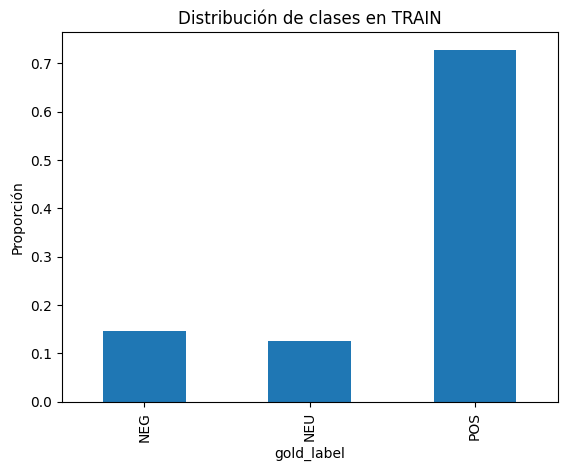

In [ ]:
import matplotlib.pyplot as plt

# Visualizar proporciones de clases en el set de entrenamiento
train_df['gold_label'] \
    .value_counts(normalize=True) \
    .reindex(['NEG', 'NEU', 'POS']) \
    .plot(kind='bar', title='Distribución de clases en TRAIN')

plt.ylabel('Proporción')
plt.show()


In [ ]:
# Distribución de proporción de cada clase en los splits
print("Train:\n", train_df['gold_label'].value_counts(normalize=True), "\n")
print("Dev:\n",   dev_df  ['gold_label'].value_counts(normalize=True), "\n")
print("Test:\n",  test_df ['gold_label'].value_counts(normalize=True), "\n")


Train:
 gold_label
POS    0.727867
NEG    0.147004
NEU    0.125129
Name: proportion, dtype: float64 

Dev:
 gold_label
POS    0.728123
NEG    0.146946
NEU    0.124931
Name: proportion, dtype: float64 

Test:
 gold_label
POS    0.727723
NEG    0.146865
NEU    0.125413
Name: proportion, dtype: float64 



### Visualización gráfica de las distribuciones

Podemos ver la proporción de cada clase por split, en todo el dataset, o por estrellas.

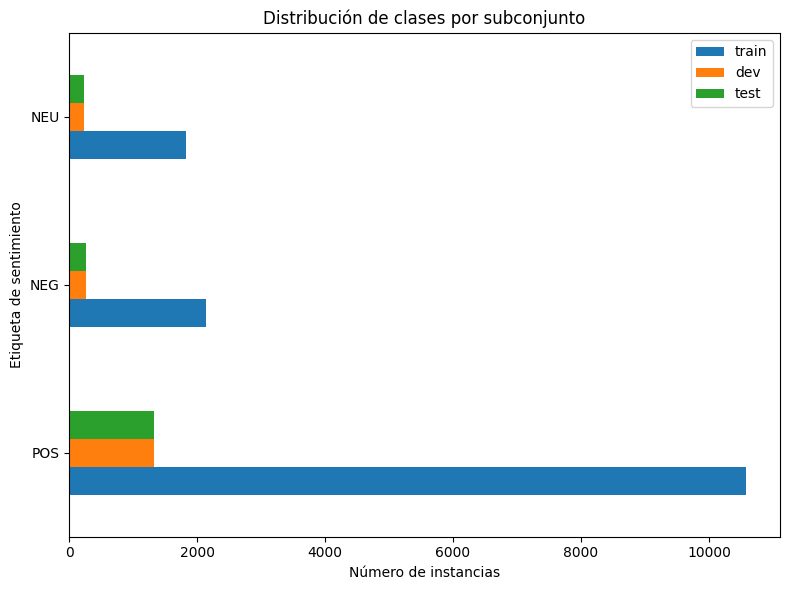

In [ ]:
# Distribución de clases por subconjunto (train, dev, test)

import matplotlib.pyplot as plt
import pandas as pd

# Crear un nuevo DataFrame con los tamaños por clase y por subconjunto
split_distribution = {
    'train': train_df['gold_label'].value_counts(),
    'dev':   dev_df  ['gold_label'].value_counts(),
    'test':  test_df ['gold_label'].value_counts()
}

# Convertir a DataFrame para mejor visualización
split_dist_df = pd.DataFrame(split_distribution).fillna(0).astype(int)

# Graficar
split_dist_df.plot(kind='barh', figsize=(8, 6))
plt.title("Distribución de clases por subconjunto")
plt.xlabel("Número de instancias")
plt.ylabel("Etiqueta de sentimiento")
plt.tight_layout()
plt.show()


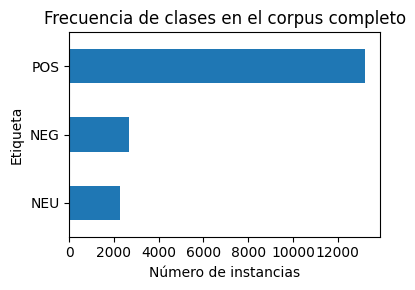

In [ ]:
import matplotlib.pyplot as plt

# Ajustar tamaño de figura antes de graficar
plt.rcParams['figure.figsize'] = [4, 3]

# Distribución de instancias por clase de sentimiento en el corpus completo
df['gold_label'] \
    .value_counts(ascending=True) \
    .plot.barh()

plt.title("Frecuencia de clases en el corpus completo")
plt.xlabel("Número de instancias")
plt.ylabel("Etiqueta")
plt.tight_layout()
plt.show()


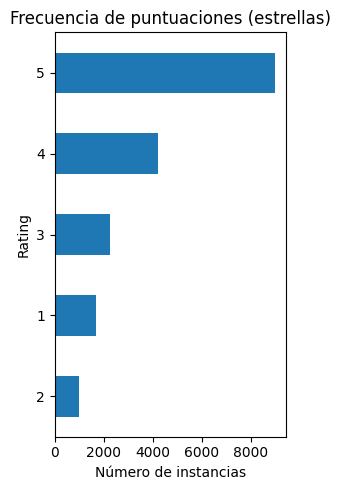

In [ ]:
import matplotlib.pyplot as plt

# Ajustar tamaño de figura antes de graficar
plt.rcParams['figure.figsize'] = [3, 5]

# Distribución de instancias por puntuación (rating de 0 a 5 estrellas)
df["rating"] \
    .value_counts(ascending=True) \
    .plot.barh()

plt.title("Frecuencia de puntuaciones (estrellas)")
plt.xlabel("Número de instancias")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()


### Selección de columnas relevantes

Seleccionamos las columnas que serán más relevantes para el entrenamiento y nuestro análisis

In [ ]:
# Nos quedamos con las columnas relevantes para el análisis
df = df[['text_full', 'rating', 'gold_label', 'split']]
df.head()


,text_full,rating,gold_label,split
0,Excelente y personal amable. Un hotel muy buen...,5,POS,train
1,Céntrico. Muy buen hotel al nivel de lo espera...,4,POS,test
2,Hotel excepcional. Magnífico hotel. La verdad ...,5,POS,train
3,"WOW!!. Hotel hermoso, buen diseño, original, l...",5,POS,train
4,Magnifico. Magnífica ubicación en pleno centro...,5,POS,dev


Aleatorizamos los conjuntos de datos, que estaban ordenados en función del número de estrellas.

In [ ]:
# Crear subconjuntos de nuevo desde df, con las columnas relevantes
columnas = ['text_full', 'rating', 'gold_label', 'split']

train_df = df[df['split'] == 'train'][columnas].sample(frac=1, random_state=SEED).reset_index(drop=True)
dev_df = df[df['split'] == 'dev'][columnas].sample(frac=1, random_state=SEED).reset_index(drop=True)
test_df = df[df['split'] == 'test'][columnas].sample(frac=1, random_state=SEED).reset_index(drop=True)

# Mostrar una muestra del conjunto de entrenamiento
train_df.head()

,text_full,rating,gold_label,split
0,Excelente Hostel en zona Alfalfa Sevilla!!!. F...,5,POS,train
1,ES UN 3 ***. Este hotel se presenta como un ho...,2,NEG,train
2,Casi me encanta.. . El apartamento un 10. Ubic...,4,POS,train
3,"Normalito. Me acabo de ir del hotel, y la verd...",3,NEU,train
4,:). Es la tercera vez que voy cuando viajo a C...,4,POS,train


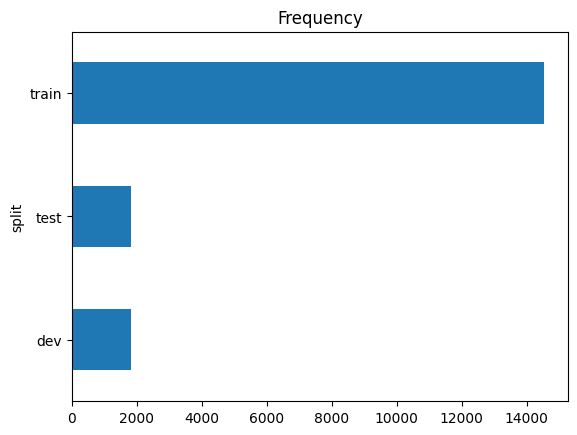

In [ ]:
# Distribución de instancias por split

import matplotlib.pyplot as plt

df["split"].value_counts(ascending=True).plot.barh()
plt.title("Frequency")
plt.rcParams['figure.figsize'] = [10, 80]
plt.show()

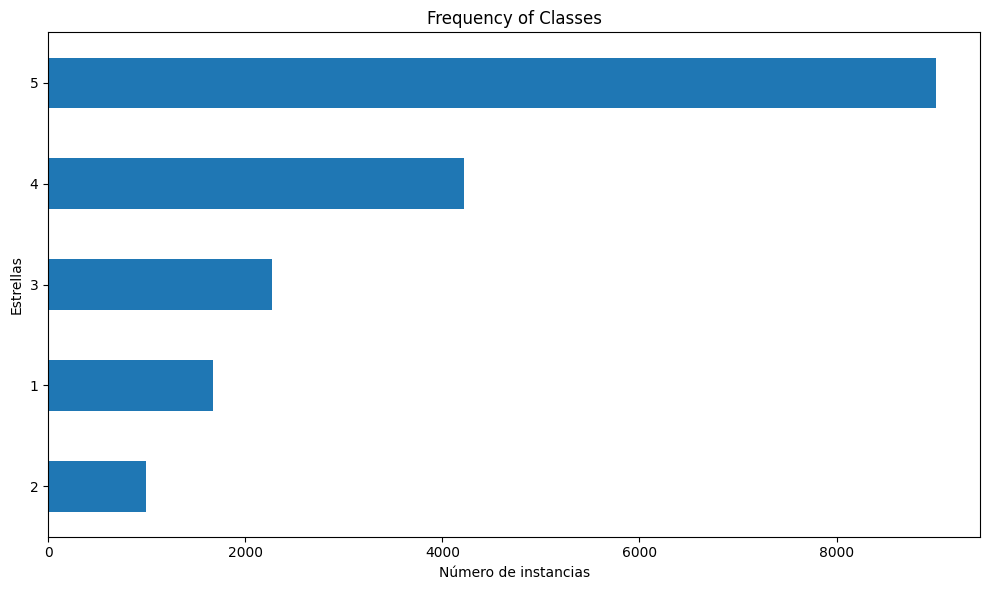

In [ ]:
# Distribución de instancias por clases (i.e. estrellas)
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))                          # Ajusta el tamaño para que quepa en pantalla
df["rating"].value_counts(ascending=True).plot.barh()
plt.title("Frequency of Classes")
plt.xlabel("Número de instancias")
plt.ylabel("Estrellas")
plt.tight_layout()                                    # Ajusta márgenes automáticamente
plt.show()


Vamos a dividir nuevamente el dataframe en tres y aleatorizar los conjuntos de datos, que estaban ordenados en función del número de estrellas.

In [ ]:
# Crear subconjuntos de nuevo desde df, con las columnas relevantes
columnas = ['text_full', 'rating', 'gold_label', 'split']

train_df = df[df['split'] == 'train'][columnas].sample(frac=1, random_state=SEED).reset_index(drop=True)
dev_df = df[df['split'] == 'dev'][columnas].sample(frac=1, random_state=SEED).reset_index(drop=True)
test_df = df[df['split'] == 'test'][columnas].sample(frac=1, random_state=SEED).reset_index(drop=True)

# Mostrar una muestra del conjunto de entrenamiento
train_df.head()

,text_full,rating,gold_label,split
0,Excelente Hostel en zona Alfalfa Sevilla!!!. F...,5,POS,train
1,ES UN 3 ***. Este hotel se presenta como un ho...,2,NEG,train
2,Casi me encanta.. . El apartamento un 10. Ubic...,4,POS,train
3,"Normalito. Me acabo de ir del hotel, y la verd...",3,NEU,train
4,:). Es la tercera vez que voy cuando viajo a C...,4,POS,train


In [ ]:
X_train = train_df['text_full']
X_dev = dev_df['text_full']
X_test = test_df['text_full']

X_train

,text_full
0,Excelente Hostel en zona Alfalfa Sevilla!!!. F...
1,ES UN 3 ***. Este hotel se presenta como un ho...
2,Casi me encanta.. . El apartamento un 10. Ubic...
3,"Normalito. Me acabo de ir del hotel, y la verd..."
4,:). Es la tercera vez que voy cuando viajo a C...
...,...
14532,Gran experiencia. Hermoso lugar y gran ubicaci...
14533,Hotel familiar y pefecta ubicación. Hotel perf...
14534,Decepcionante. Hemos llegado hoy y ha sido un ...
14535,a lovely place to stay if driving between sevi...


# Aprendizaje transferido con Transformadores

Vamos a utilizar la librería Transformers de Hugging Face para entrenar un modelo de clasificación de secuencias utilizando un modelo de transformador preentrenado. Con su tokenizador preprocesaremos el texto.
  
   

In [ ]:
from datasets import Dataset, DatasetDict

# 1) Asegúrate de que train_df, dev_df y test_df existen:
print(f"Shapes: train {train_df.shape}, dev {dev_df.shape}, test {test_df.shape}")

# 2) Mapea de nuevo las etiquetas a números
label2id = {"NEG": 0, "NEU": 1, "POS": 2}
for split_df in (train_df, dev_df, test_df):
    split_df["labels"] = split_df["gold_label"].map(label2id)

# 3) Crea los HuggingFace Datasets
hf_train = Dataset.from_pandas(train_df)
hf_dev   = Dataset.from_pandas(dev_df)
hf_test  = Dataset.from_pandas(test_df)

# 4) Ahora sí, el DatasetDict
dataset = DatasetDict({
    "train": hf_train,
    "validation": hf_dev,
    "test": hf_test
})

# Compruébalo:
print(dataset)


Shapes: train (14537, 4), dev (1817, 4), test (1818, 4)
DatasetDict({
    train: Dataset({
        features: ['text_full', 'rating', 'gold_label', 'split', 'labels'],
        num_rows: 14537
    })
    validation: Dataset({
        features: ['text_full', 'rating', 'gold_label', 'split', 'labels'],
        num_rows: 1817
    })
    test: Dataset({
        features: ['text_full', 'rating', 'gold_label', 'split', 'labels'],
        num_rows: 1818
    })
})


In [ ]:
from transformers import AutoTokenizer
from datasets import DatasetDict

# Usamos el BERT en español que ya definimos antes
MODEL_NAME = "dccuchile/bert-base-spanish-wwm-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Montamos un DatasetDict con los splits que ya teníamos
dataset = DatasetDict({
    "train": hf_train,
    "validation": hf_dev,
    "test": hf_test
})

# Función de tokenización adaptada a nuestra columna `text_full`
def tokenize(examples):
    return tokenizer(
        examples["text_full"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

# Aplicamos tokenización a todos los splits de una vez
tokenized_ds = dataset.map(tokenize, batched=True)

tokenized_ds


Map:   0%|          | 0/14537 [00:00<?, ? examples/s]

Map:   0%|          | 0/1817 [00:00<?, ? examples/s]

Map:   0%|          | 0/1818 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text_full', 'rating', 'gold_label', 'split', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 14537
    })
    validation: Dataset({
        features: ['text_full', 'rating', 'gold_label', 'split', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1817
    })
    test: Dataset({
        features: ['text_full', 'rating', 'gold_label', 'split', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1818
    })
})

In [ ]:
from transformers import AutoModelForSequenceClassification
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,                   # BERT en español
    num_labels=len(label2id),     # 3 clases: NEG, NEU, POS
    id2label={v:k for k,v in label2id.items()},
    label2id=label2id
).to(device)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
ds = tokenized_ds
ds['train'][0]

{'text_full': 'Excelente Hostel en zona Alfalfa Sevilla!!!. Fue una buena opción por lo económico , por la ubicación, estabamos cerca de muchas cosas para ir caminando, teníamos un alquiler de Bicis a la vuelta, el desayuno es bueno, la atención también, es tranquilo y está cerca de la plaza alfalfa, adonde hay varios bares y lugares para comer Tapas.',
 'rating': 5,
 'gold_label': 'POS',
 'split': 'train',
 'labels': 2,
 'input_ids': [4,
  5556,
  2978,
  2266,
  1035,
  2911,
  12962,
  30962,
  2794,
  10471,
  1109,
  1109,
  1109,
  1008,
  1247,
  1091,
  2245,
  5418,
  1076,
  1086,
  3572,
  1019,
  1076,
  1032,
  8394,
  1019,
  24003,
  2611,
  1009,
  2458,
  1836,
  1097,
  1476,
  10882,
  1019,
  7430,
  1044,
  6510,
  1009,
  9119,
  30958,
  1012,
  1032,
  3440,
  1019,
  1039,
  9124,
  1028,
  1491,
  1019,
  1032,
  2857,
  1356,
  1019,
  1028,
  5563,
  1040,
  1157,
  2611,
  1009,
  1032,
  5450,
  12962,
  30962,
  2794,
  1019,
  12612,
  1311,
  2909,
  16

Definimos las métricas de evaluación mediante una función compute_metrics que se utiliza para calcular varias métricas de rendimiento para un modelo de clasificación. Esta función toma una tupla eval_pred como entrada y devuelve un diccionario con las métricas de rendimiento calculadas.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    # Convertimos los logits a predicciones de clase
    preds = np.argmax(logits, axis=-1)
    # Calculamos accuracy y F1 macro
    acc = accuracy_score(labels, preds)
    macro_f1 = f1_score(labels, preds, average='macro')
    return {
        "accuracy": acc,
        "macro_f1": macro_f1
    }


Este código es utilizado para entrenar un modelo de transformadores utilizando la clase Trainer.

En primer lugar, se establecen algunos parámetros de entrenamiento, como el tamaño del lote, el nombre del modelo finetuned, el número de épocas de entrenamiento, la tasa de aprendizaje, la relación de calentamiento, la tasa de decaimiento del peso, la estrategia de evaluación, la estrategia de guardado, la métrica para el mejor modelo y la opción de cargar el mejor modelo al final del entrenamiento. Estos parámetros se almacenan en la variable training_args utilizando la clase TrainingArguments de transformers.


In [ ]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

# 1. Ajustes básicos
batch_size = 16
output_dir = "finetuned_bert_spanish_sentiment"

# 2. Calcula cuántos pasos hay por epoch (nº de muestras // batch_size)
steps_per_epoch = len(ds["train"]) // batch_size

# 3. Define los argumentos de entrenamiento en modo “legacy”
training_args = TrainingArguments(
    output_dir=output_dir,
    num_train_epochs=5,
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    warmup_ratio=0.1,
    weight_decay=0.01,

    # Legacy evaluation & saving
    do_train=True,
    do_eval=True,
    eval_steps=steps_per_epoch,   # eval tras cada epoch
    save_steps=steps_per_epoch,   # checkpoint tras cada epoch

    save_total_limit=1,           # conserva solo 1 checkpoint
    report_to="none",             # desactiva W&B
)

# 4. Data collator para padding dinámico
data_collator = DataCollatorWithPadding(tokenizer)

# 5. Construye el Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    compute_metrics=compute_metrics,
    train_dataset=ds["train"],        # split de entrenamiento
    eval_dataset=ds["validation"],    # split de validación
    data_collator=data_collator
)

# 6. Entrena
trainer.train()


Step,Training Loss
500,0.450700
1000,0.285700
1500,0.213300
2000,0.159800
2500,0.124900
3000,0.079200
3500,0.062700
4000,0.031900
4500,0.024700


TrainOutput(global_step=4545, training_loss=0.1577907086074418, metrics={'train_runtime': 1813.3637, 'train_samples_per_second': 40.083, 'train_steps_per_second': 2.506, 'total_flos': 4781099691889920.0, 'train_loss': 0.1577907086074418, 'epoch': 5.0})

Dado que el entrenamiento ha llevado 30 minutos, guardamos el modelo en Drive por si fuese necesario interrumpir la tarea y retomar sesión en otro momento.

In [ ]:
# 1) Monta tu Drive (si aún no lo hiciste)
from google.colab import drive
drive.mount('/content/drive')

# 2) Elige una carpeta donde salvar tu modelo
output_dir = "/content/drive/MyDrive/0.Apuntes PLN/finetuned_bert_spanish"

# 3) Guarda el modelo y el tokenizador
trainer.save_model(output_dir)             # guarda model.bin + config.json
tokenizer.save_pretrained(output_dir)      # guarda vocabulario y config

# 4) (Opcional) guarda también el estado del Trainer:
trainer.state.save_to_json(f"{output_dir}/trainer_state.json")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Evaluamos el mejor modelo entrenado en el conjunto de prueba y obtenemos las métricas de evaluación.

In [ ]:
from datasets import Dataset

# 1) Mapea las etiquetas a números
test_df["labels"] = test_df["gold_label"].map(label2id)

# 2) Crea el HF Dataset
hf_test = Dataset.from_pandas(test_df)

# 3) Tokeniza y elimina las columnas sobrantes
def tokenize_fn(examples):
    return tokenizer(
        examples["text_full"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

hf_test = hf_test.map(
    tokenize_fn,
    batched=True,
    remove_columns=["text_full", "rating", "gold_label", "split"]
)

# 4) Formatea para PyTorch
hf_test.set_format("torch", columns=["input_ids", "attention_mask", "labels"])


Map:   0%|          | 0/1818 [00:00<?, ? examples/s]

In [ ]:
preds_out = trainer.predict(hf_test)
print(preds_out.metrics)


{'test_loss': 0.40466630458831787, 'test_accuracy': 0.9312431243124313, 'test_macro_f1': 0.8693044833795995, 'test_runtime': 11.766, 'test_samples_per_second': 154.512, 'test_steps_per_second': 9.689}


Obtenemos el informe de clasificación global y detallado de las predicciones hechas por el mejor modelo en función de las clases.

In [ ]:
preds_output = trainer.predict(hf_test)


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

# 1) Extrae las etiquetas verdaderas del conjunto de test
#    (aquí ‘hf_test’ es el Dataset tokenizado con la columna “labels”)
y_true = np.array(hf_test["labels"])

# 2) Obtén las predicciones de clase a partir de los logits devueltos
#    por trainer.predict(hf_test)
y_pred = preds_output.predictions.argmax(axis=-1)

# 3) Define los nombres de tus clases en el mismo orden que label2id
target_names = ["NEG", "NEU", "POS"]

# 4) Calcula e imprime el informe detallado
report = classification_report(
    y_true,
    y_pred,
    target_names=target_names
)
print(report)


              precision    recall  f1-score   support

         NEG       0.93      0.90      0.91       267
         NEU       0.74      0.71      0.73       228
         POS       0.96      0.98      0.97      1323

    accuracy                           0.93      1818
   macro avg       0.88      0.86      0.87      1818
weighted avg       0.93      0.93      0.93      1818



* **NEG (negativas)**

  * Precision 0.93 → cuando predice NEG, acierta el 93 % de las veces.
  * Recall 0.90 → recupera el 90 % de todas las NEG reales.
  * F1 0.91 → muy buen equilibrio.

* **NEU (neutras)**

  * Precision 0.74 y Recall 0.71 → aquí es donde más se “dispara” el error:

    * El 26 % de las predicciones de NEU son en realidad POS o NEG.
    * Captura solo el 71 % de las verdaderas NEU.
  * F1 0.73 → claramente la clase más débil.

* **POS (positivas)**

  * Precision 0.96 y Recall 0.98 → casi no comete falsos positivos ni falsos negativos.
  * F1 0.97 → sobresaliente.

* **Globales**

  * Accuracy 0.93 → 93 % de acierto en total.
  * Macro-avg F1 0.87 → promedia igual las tres clases (refleja la caída de NEU).

---

## Conclusiones y siguientes pasos

1. **Desbalance de clases**
   La clase NEU es la menos representada y también la más difícil de distinguir (los comentarios “planos” tienden a confundirse con leves positivos o negativos).

2. **Estrategias para mejorar NEU**

   * Aumentar ejemplos NEU (data augmentation o recolección adicional).
   * Ajustar pesos en pérdida (`class_weight`) para penalizar más los errores en NEU.
   * Crear reglas heurísticas o features lexicón específicos para expresiones neutrales (p. ej. frases descriptivas sin valoraciones).

3. **Analizar ejemplos de fallo**

   Extraer las instancias donde el modelo predice mal NEU (o POS ↔ NEG) y examinar patrones de lenguaje que confundan, para luego diseñar features o reglas que ayuden al modelo a diferenciarlas.

En conjunto, el modelo generaliza muy bien en POS y NEG, pero la clase NEU requiere atención específica para alcanzar un rendimiento más equilibrado.


In [ ]:
import torch
import pandas as pd

# 1) Poner el modelo en modo evaluación
model.eval()

# 2) Inicializar listas
losses = []
predictions = []

# 3) Recorremos el tokenized dataset de test
for i in range(len(ds["test"])):
    sample = ds["test"][i]
    # Preparamos las entradas
    inputs = {
        "input_ids":      torch.tensor(sample["input_ids"]).unsqueeze(0).to(model.device),
        "attention_mask": torch.tensor(sample["attention_mask"]).unsqueeze(0).to(model.device)
    }
    # Preparamos la etiqueta
    label = torch.tensor(sample["labels"]).unsqueeze(0).to(model.device)

    # Inferencia sin gradientes
    with torch.no_grad():
        outputs = model(**inputs, labels=label)

    # Extraemos loss y predicción
    losses.append(outputs.loss.item())
    predictions.append(torch.argmax(outputs.logits, dim=-1).item())

# 4) Creamos un DataFrame copia de test_df y añadimos columnas
df_test = test_df.copy()  # test_df es tu pandas con text_full, rating, gold_label…
df_test["predicted_label_id"] = predictions
# Si quieres la etiqueta en texto, mapea de nuevo usando label2id invertido:
id2label = {v: k for k, v in label2id.items()}
df_test["predicted_label"] = df_test["predicted_label_id"].map(id2label)
df_test["loss"] = losses

# 5) Ordenamos de mayor a menor por la pérdida
df_test = df_test.sort_values(by="loss", ascending=False)

# 6) Vemos las primeras filas
df_test.head()


,text_full,rating,gold_label,split,labels,predicted_label_id,predicted_label,loss
473,"3 giorni Siviglia. Appartamento carino, mobili...",3,NEU,test,1,2,POS,9.658760
1074,Hostal las dunas. Hostal muy sencillo con poco...,3,NEU,test,1,2,POS,9.294236
1588,Visita a Cazorla! La Matea. Restaurante en la ...,3,NEU,test,1,2,POS,9.188758
498,Viaje en familia. El establecimiento está en p...,3,NEU,test,1,2,POS,9.123156
411,"Graduación . Es muy chulo, limpio , situación ...",3,NEU,test,1,2,POS,9.107926


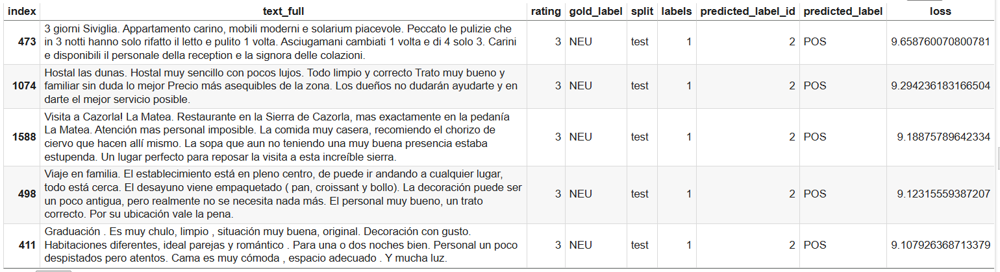

# Ajuste de hiperparámetros

Una vez hemos ajustado el transformador preentrenado, probaremos si es posible mejorar un poco más los resultados.

Entre los parámetros que podríamos probar, se encuentran los siguientes (igual que en la tarea que ya hicimos para este tema):

-         Número de épocas: 3-5-10

-         Learning rate: 2e-5, 5e-5, 10e-5

-         Weight decay: 0.01, 0.05, 0.1


Esto daría en total 27 entrenamientos (3 niveles de épocas x 3 tasas de aprendizaje x 3 weight-decay).

Con la ejecución de los 2 primeros experimentos, veo que cada entrenamiento lleva unos 20 minutos. Teniendo en cuenta que serían en total 27, me parece una cantidad de tiempo desmesurado, por lo que decido realizar únicamente 4 experimentos en total (que se llamarán: 1/27, 1/27, A y B).



Para proceder a los diferentes experimentos, añadiremos una función de ayuda para ejecutar múltiples experimentos de fine-tuning de Transformes y evitar duplicar código en cada ocasión.

In [ ]:
# Con esto, en cada experimento sólo llamamos a run_sentiment_experiment(...) en lugar de copiar toda la celda.
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

def run_sentiment_experiment(epochs, lr, wd, drive_model_dir, base_output_dir="results"):
    # 1) Construye un nombre único para este experimento
    exp_name = f"exp_ep{epochs}_lr{lr}_wd{wd}".replace(".", "p")
    output_dir = f"{base_output_dir}/{exp_name}"

    # 2) Calcula pasos por epoch (legacy)
    steps_per_epoch = len(ds["train"]) // batch_size

    # 3) Define los argumentos de entrenamiento
    args = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        warmup_ratio=0.1,
        weight_decay=wd,

        # legacy evaluation & saving cada epoch
        do_train=True,
        do_eval=True,
        eval_steps=steps_per_epoch,
        save_steps=steps_per_epoch,
        save_total_limit=1,
        report_to="none",
    )

    # 4) model_init cargando tu modelo desde Drive
    def model_init():
        return AutoModelForSequenceClassification.from_pretrained(
            drive_model_dir,
            num_labels=len(label2id),
            id2label={v:k for k,v in label2id.items()},
            label2id=label2id
        )

    # 5) Data collator para padding dinámico
    collator = DataCollatorWithPadding(tokenizer)

    # 6) Construye el Trainer
    trainer = Trainer(
        model_init=model_init,
        args=args,
        compute_metrics=compute_metrics,
        train_dataset=ds["train"],
        eval_dataset=ds["validation"],
        data_collator=collator
    )

    # 7) Entrena
    trainer.train()

    # 8) Evalúa sobre validation y devuelve métricas
    val_metrics = trainer.evaluate(ds["validation"])
    return exp_name, val_metrics




In [ ]:
# — Experimento 1/27 —
# épocas = 3, lr = 2e-5, weight_decay = 0.01
drive_model_dir = "/content/drive/MyDrive/0.Apuntes PLN/finetuned_bert_spanish"
metrics_1 = run_sentiment_experiment(
    epochs=3,
    lr=2e-5,
    wd=0.01,
    drive_model_dir=drive_model_dir
)
print("experimento 1 (ep=3, lr=2e-5, wd=0.01):", metrics_1)


Step,Training Loss
500,0.050700
1000,0.049100
1500,0.034100
2000,0.020900
2500,0.014600


experimento 1 (ep=3, lr=2e-5, wd=0.01): ('exp_ep3_lr2e-05_wd0p01', {'eval_loss': 0.5394150018692017, 'eval_accuracy': 0.9306549257017062, 'eval_macro_f1': 0.861485669492918, 'eval_runtime': 12.8961, 'eval_samples_per_second': 140.896, 'eval_steps_per_second': 8.84, 'epoch': 3.0})


Pérdida en validación (eval_loss): 0.5394

Exactitud (eval_accuracy): 93.07 %

Macro-F1 (eval_macro_f1): 0.8615

Estos resultados muestran que, tras 3 épocas con lr=2e-5 y weight_decay=0.01, el modelo acierta más del 93 % de las muestras y obtiene un F1-macro equilibrado de alrededor de 0.86.

In [ ]:
# Ejecutar Experimento 2/27:
#    épocas = 3, lr = 2e-5, weight_decay = 0.05
drive_model_dir = "/content/drive/MyDrive/0.Apuntes PLN/finetuned_bert_spanish"
metrics_2 = run_sentiment_experiment(
    epochs=3,
    lr=2e-5,
    wd=0.05,
    drive_model_dir=drive_model_dir
)
print("Experimento 2 (ep=3, lr=2e-5, wd=0.05):", metrics_2)

Step,Training Loss
500,0.044500
1000,0.050700
1500,0.039800
2000,0.016800
2500,0.013300


Experimento 2 (ep=3, lr=2e-5, wd=0.05): ('exp_ep3_lr2e-05_wd0p05', {'eval_loss': 0.5489641427993774, 'eval_accuracy': 0.9273527793065492, 'eval_macro_f1': 0.8553182131163095, 'eval_runtime': 12.2483, 'eval_samples_per_second': 148.347, 'eval_steps_per_second': 9.307, 'epoch': 3.0})


Pérdida en validación (eval\_loss): 0.5490

Exactitud (eval\_accuracy): 92.74 %

Macro-F1 (eval\_macro\_f1): 0.8553

Estos resultados muestran que, tras 3 épocas con lr=2e-5 y weight\_decay=0.05, el modelo acierta alrededor del 92.7 % de las muestras y mantiene un F1-macro equilibrado de aproximadamente 0.86, ligeramente inferior al experimento con menor regularización.


Observando que cada experimento tarda unos 20 minutos en ejecutarse. Decido que, en lugar de las 27 configuraciones, solamente probaré dos más y así obtener un total de 4 experimentos para decidir qué versión del modelo refinado utilizaremos para el resto de la tarea.
Los dos experimentos que faltan serán A y B.

In [ ]:
drive_model_dir = "/content/drive/MyDrive/0.Apuntes PLN/finetuned_bert_spanish"

# Experimento A: 5 epochs, lr=2e-5, wd=0.01
expA, mA = run_sentiment_experiment(
    epochs=5,
    lr=2e-5,
    wd=0.01,
    drive_model_dir=drive_model_dir
)
print(f"{expA}: {mA}")

# Experimento B: 3 epochs, lr=5e-5, wd=0.01
expB, mB = run_sentiment_experiment(
    epochs=3,
    lr=5e-5,
    wd=0.01,
    drive_model_dir=drive_model_dir
)
print(f"{expB}: {mB}")

Step,Training Loss
500,0.034300
1000,0.057000
1500,0.049100
2000,0.037800
2500,0.030900
3000,0.014900
3500,0.014700
4000,0.003900
4500,0.009500


exp_ep5_lr2e-05_wd0p01: {'eval_loss': 0.6395127177238464, 'eval_accuracy': 0.9251513483764446, 'eval_macro_f1': 0.856613824532606, 'eval_runtime': 11.865, 'eval_samples_per_second': 153.14, 'eval_steps_per_second': 9.608, 'epoch': 5.0}


Step,Training Loss
500,0.138200
1000,0.155100
1500,0.096800
2000,0.065800
2500,0.031100


exp_ep3_lr5e-05_wd0p01: {'eval_loss': 0.4946335554122925, 'eval_accuracy': 0.9201981287837094, 'eval_macro_f1': 0.8435355065080915, 'eval_runtime': 12.8672, 'eval_samples_per_second': 141.212, 'eval_steps_per_second': 8.86, 'epoch': 3.0}


**Experimento A**

Pérdida en validación (eval\_loss): 0.6395

Exactitud (eval\_accuracy): 92.52 %

Macro-F1 (eval\_macro\_f1): 0.8566

Estos resultados muestran que, tras 5 épocas con lr=2e-5 y weight\_decay=0.01, el modelo acierta aproximadamente el 92.5 % de las muestras y obtiene un F1-macro de alrededor de 0.86, ligeramente por debajo del punto óptimo alcanzado en 3 épocas.

**Experimento B**

Pérdida en validación (eval_loss): 0.4946

Exactitud (eval_accuracy): 92.02 %

Macro-F1 (eval_macro_f1): 0.8435

Estos resultados muestran que, tras 3 épocas con lr=5e-5 y weight_decay=0.01, el modelo acierta alrededor del 92.0 % de las muestras y obtiene un F1-macro de aproximadamente 0.84, indicando un ligero descenso en el equilibrio entre clases con respecto a las configuraciones de lr más bajas.

## Comparación de los 4 experimentos

1/27: 3 ep, lr=2e-5, wd=0.01 → F1≈0.8615

2/27: 3 ep, lr=2e-5, wd=0.05 → F1≈0.8553

A: 5 ep, lr=2e-5, wd=0.01 → F1≈0.8566

B: 3 ep, lr=5e-5, wd=0.01 → F1≈0.8435

El mejor resultado de validación lo obtenemos con el experimento 1 (3 ep, lr=2e-5, wd=0.01).

#### Comentario sobre el progreso de la tarea.

Tras varias horas configurando el cuaderno y entrenando el modelo y los 4 experimentos, llegados a este punto, ya tenía que cerrar sesión. Al retomar el cuaderno en este punto, veo que no tengo guardados los diferentes modelos de los experimentos, especialmente el 1, que era el que obtenía mejor macro-F1 y era el que nos interesaba.

### Reentrenamos el experimento 1 para recuperarlo y poder evaluarlo



In [ ]:
# --- Re-entrenar Experimento 1: 3 epochs, lr=2e-5, wd=0.01 partiendo de tu modelo en Drive ---

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# 1) Ruta al modelo base fine-tuned (5 ep originales)
drive_model_dir = "/content/drive/MyDrive/0.Apuntes PLN/finetuned_bert_spanish"

# 2) Recarga ese checkpoint como punto de partida
model_1 = AutoModelForSequenceClassification.from_pretrained(
    drive_model_dir,
    num_labels=len(label2id),
    id2label={v:k for k,v in label2id.items()},
    label2id=label2id
).to(device)

# 3) Argumentos de entrenamiento para el Experimento 1
batch_size = 16
steps_per_epoch = len(ds["train"]) // batch_size

training_args_1 = TrainingArguments(
    output_dir="results/exp1_ep3_lr2e-5_wd0p01",  # carpeta de salida única
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    warmup_ratio=0.1,
    weight_decay=0.01,

    # legacy eval/save cada epoch
    do_train=True,
    do_eval=True,
    eval_steps=steps_per_epoch,
    save_steps=steps_per_epoch,
    save_total_limit=1,
    logging_steps=steps_per_epoch,
    report_to="none",
)

# 4) Data collator
data_collator = DataCollatorWithPadding(tokenizer)

# 5) Construye y lanza el Trainer para el Experimento 1
trainer_1 = Trainer(
    model=model_1,
    args=training_args_1,
    compute_metrics=compute_metrics,
    train_dataset=ds["train"],
    eval_dataset=ds["validation"],
    data_collator=data_collator
)

trainer_1.train()                  # fine-tune 3 epochs
metrics_1 = trainer_1.evaluate()  # evalúa en validación
print("Resultados Experimento 1:", metrics_1)


Step,Training Loss
908,0.051300
1816,0.032100
2724,0.013000


Resultados Experimento 1: {'eval_loss': 0.5394150018692017, 'eval_accuracy': 0.9306549257017062, 'eval_macro_f1': 0.861485669492918, 'eval_runtime': 13.3433, 'eval_samples_per_second': 136.173, 'eval_steps_per_second': 8.544, 'epoch': 3.0}


### Evaluación del mejor modelo: experimento 1
Una vez hemos reentrenado el experimento 1 para recuperarlo (y viendo que los resultados son exactamente iguales), procedemos a evaluarlo.

In [ ]:
import os
import torch
import numpy as np
from sklearn.metrics import accuracy_score, classification_report
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# 1) Monta Drive (si no está montado)
from google.colab import drive
drive.mount('/content/drive')

# 2) Carpeta de Exp1
output_dir = "results/exp1_ep3_lr2e-5_wd0p01"
ckpts = [d for d in os.listdir(output_dir) if d.startswith("checkpoint-")]
ckpt_dir = os.path.join(output_dir, sorted(ckpts)[-1])

# 3) Recarga modelo y tokenizer
device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model1     = AutoModelForSequenceClassification.from_pretrained(ckpt_dir).to(device)
tokenizer1 = AutoTokenizer.from_pretrained(ckpt_dir)

# 4) Tokeniza tu test_df de una vez
texts = test_df["text_full"].tolist()
labels = torch.tensor(test_df["labels"].tolist())

enc = tokenizer1(
    texts,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

# 5) Crea TensorDataset y DataLoader sin collator
ds_test = TensorDataset(enc["input_ids"], enc["attention_mask"], labels)
loader  = DataLoader(ds_test, batch_size=16, shuffle=False)

# 6) Inferencia
model1.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for input_ids, attention_mask, lbls in loader:
        input_ids      = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        logits         = model1(input_ids=input_ids, attention_mask=attention_mask).logits
        preds          = torch.argmax(logits, dim=-1).cpu()
        all_preds.append(preds)
        all_labels.append(lbls)

# 7) Consolida resultados y muestra métricas
y_true = torch.cat(all_labels).numpy()
y_pred = torch.cat(all_preds).numpy()

print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4f}\n")
print("Classification report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["NEG","NEU","POS"]
))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Test accuracy: 0.9301

Classification report:
              precision    recall  f1-score   support

         NEG       0.92      0.91      0.92       267
         NEU       0.74      0.72      0.73       228
         POS       0.96      0.97      0.97      1323

    accuracy                           0.93      1818
   macro avg       0.88      0.87      0.87      1818
weighted avg       0.93      0.93      0.93      1818



Accuracy: 0.93 → 93 % de acierto global.

Macro-avg F1: 0.87 → buen rendimiento equilibrado entre clases.

Weighted-avg F1: 0.93 → reflejando el dominio de la clase POS.

Conclusiones

El modelo predice muy bien NEG y POS, con F1 ≈ 0.92–0.97.

Sigue costándole más distinguir NEU (F1 ≈ 0.73), seguramente por su menor representación y la ambigüedad inherente de las reseñas neutras. Pero cabe destacar que el rendimiento es mucho mejor que en cuadernos previos como, por ejemplo, para los modelos con lexicón o de regresión logística.

## Comparación con los resultados de evaluación del modelo original (antes de las configuraciones)

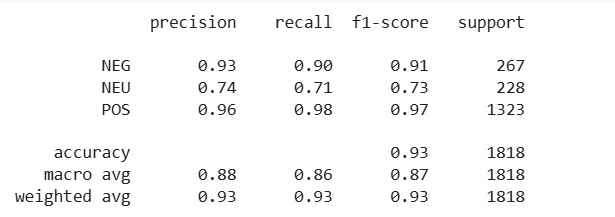

Los resultados son prácticamente idénticos: las diferencias están en la tercera cifra decimal (±0.01) para NEU-recall y POS-recall.

Experimento 1/27 (3 ep) logra el mismo rendimiento global que el modelo original (5 ep), pero con menor tiempo de entrenamiento.

Conclusión:
Dado que 3 épocas bastan para alcanzar el mismo nivel de desempeño que 5 épocas, conviene quedarse con el Experimento 1/27 (3 ep, lr=2e-5, wd=0.01) como  modelo definitivo y pasar al análisis cualitativo y despliegue.

Primero, lo guardaremos en Drive por si tenemos que recuperar la sesión en otro momento.

In [ ]:
# 1) Monta tu Google Drive (si no está montado)
from google.colab import drive
drive.mount('/content/drive')

# 2) Directorio donde quieres guardar el mejor modelo
best_model_dir = "/content/drive/MyDrive/0.Apuntes PLN/best_finetuned_bert_spanish"

# 3) Guarda el modelo y el tokenizador
#    Asumiendo que `trainer_1` o `model_1` es el mejor modelo (Experimento 1)
trainer_1.save_model(best_model_dir)          # guarda pytorch_model.bin + config.json
tokenizer.save_pretrained(best_model_dir)     # guarda vocabulario y configuración

print(f"Mejor modelo guardado en: {best_model_dir}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mejor modelo guardado en: /content/drive/MyDrive/0.Apuntes PLN/best_finetuned_bert_spanish


# Actualización del csv con las predicciones de cada modelo

Una vez hemos identificado la mejor configuración para este modelo, actualizamos el csv para incorporar las predicciones.

Primero ejecutamos el código para recuperar el entorno y reiniciar sesión desde este punto, para poder actualizar el csv con las predicciones de este modelo.

In [ ]:
# 1) Monta tu Drive
from google.colab import drive
drive.mount('/content/drive')

# 2) Imports
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# 3) Rutas
best_model_dir = "/content/drive/MyDrive/0.Apuntes PLN/best_finetuned_bert_spanish"
csv_paths = [
    "/content/drive/MyDrive/0.Apuntes PLN/predicciones_modelos_100.csv",
    "/content/drive/MyDrive/0.Apuntes PLN/predicciones_modelos_completo.csv"
]

# 4) Carga modelo y tokenizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = AutoModelForSequenceClassification.from_pretrained(best_model_dir).to(device)
tok    = AutoTokenizer.from_pretrained(best_model_dir)
id2label = model.config.id2label

# 5) Para cada CSV: inferencia y guardado
for path in csv_paths:
    # 5.1) Lee el CSV
    df = pd.read_csv(path)

    # 5.2) Tokeniza todo el texto de golpe
    enc = tok(
        df["text"].tolist(),
        padding="max_length",
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

    # 5.3) Prepara DataLoader
    ds     = TensorDataset(enc["input_ids"], enc["attention_mask"])
    loader = DataLoader(ds, batch_size=16, shuffle=False)

    # 5.4) Inferencia por lotes
    model.eval()
    preds = []
    with torch.no_grad():
        for input_ids, attention_mask in loader:
            input_ids      = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            logits         = model(input_ids=input_ids,
                                   attention_mask=attention_mask).logits
            batch_preds    = torch.argmax(logits, dim=-1).cpu().tolist()
            preds.extend(batch_preds)

    # 5.5) Mapea a etiquetas y añade la columna
    df["Pred.Trf"] = [id2label[p] for p in preds]

    # 5.6) Sobrescribe el CSV
    df.to_csv(path, index=False)
    print(f"✅ CSV actualizado con columna Pred.Trf: {path}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ CSV actualizado con columna Pred.Trf: /content/drive/MyDrive/0.Apuntes PLN/predicciones_modelos_100.csv
✅ CSV actualizado con columna Pred.Trf: /content/drive/MyDrive/0.Apuntes PLN/predicciones_modelos_completo.csv


Visualizamos una pequeña muestra para comprobar que están las predicciones del modelo de transformadores correctamente añadido a las predicciones del resto de modelos, tanto en el csv con la muestra de 100 reseñas como en el csv del corpus completo.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
from IPython.display import display

# 1) Define las rutas
path_100  = '/content/drive/MyDrive/0.Apuntes PLN/predicciones_modelos_100.csv'
path_full = '/content/drive/MyDrive/0.Apuntes PLN/predicciones_modelos_completo.csv'

# 2) Carga los CSV en dos variables distintas
df100  = pd.read_csv(path_100)
dffull = pd.read_csv(path_full)

# 3) Muestra de las primeras 10 filas:
print("🔹 Primeras 10 filas — predicciones_modelos_100.csv")
display(df100.head(10).reset_index(drop=True))

print("🔹 Primeras 10 filas — predicciones_modelos_completo.csv")
display(dffull.head(10).reset_index(drop=True))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🔹 Primeras 10 filas — predicciones_modelos_100.csv


,text,Real,Pred. lexicón,Pred.RegLog,Pred.Deep,Pred.Trf
0,Excelente y personal amable. Un hotel muy buen...,POS,POS,POS,POS,POS
1,Céntrico. Muy buen hotel al nivel de lo espera...,POS,NEG,POS,POS,POS
2,Hotel excepcional. Magnífico hotel. La verdad ...,POS,POS,POS,POS,POS
3,"WOW!!. Hotel hermoso, buen diseño, original, l...",POS,POS,POS,POS,POS
4,Magnifico. Magnífica ubicación en pleno centro...,POS,POS,POS,POS,POS
5,Mejor hotel de ciudad en Sevilla. Si estás bus...,POS,POS,POS,POS,POS
6,Ubicación y comodidad. Gran ubicación y una en...,POS,NEG,POS,POS,POS
7,Muy buena relación calidad-precio. Precioso ho...,POS,NEG,POS,POS,POS
8,Lo mejor su personal. Como todos los hoteles d...,POS,POS,POS,POS,POS
9,HOTEL PRECIOSO. Empiezo por lo menos agradable...,POS,POS,POS,POS,POS


🔹 Primeras 10 filas — predicciones_modelos_completo.csv


,text,Real,Pred. lexicón,Pred.RegLog,Pred.Deep,Pred.Trf
0,Excelente y personal amable. Un hotel muy buen...,POS,POS,POS,POS,POS
1,Céntrico. Muy buen hotel al nivel de lo espera...,POS,NEG,POS,POS,POS
2,Hotel excepcional. Magnífico hotel. La verdad ...,POS,POS,POS,POS,POS
3,"WOW!!. Hotel hermoso, buen diseño, original, l...",POS,POS,POS,POS,POS
4,Magnifico. Magnífica ubicación en pleno centro...,POS,POS,POS,POS,POS
5,Mejor hotel de ciudad en Sevilla. Si estás bus...,POS,POS,POS,POS,POS
6,Ubicación y comodidad. Gran ubicación y una en...,POS,NEG,POS,POS,POS
7,Muy buena relación calidad-precio. Precioso ho...,POS,NEG,POS,POS,POS
8,Lo mejor su personal. Como todos los hoteles d...,POS,POS,POS,POS,POS
9,HOTEL PRECIOSO. Empiezo por lo menos agradable...,POS,POS,POS,POS,POS


# Análisis de predicciones: cálculo de casos problemáticos

Generamos pérdidas por predicción y ordenamos el dataframe en función de las pérdidas para análisis de predicciones

In [ ]:
import pandas as pd
from IPython.display import display

# 1) Invierte tu mapa label2id para pasarlo a etiquetas textuales
inv_label2id = {v:k for k,v in label2id.items()}

# 2) Coge los 5 primeros ejemplos de df_test_sorted (ya ordenado por loss desc.)
top5 = df_test_sorted.head(5).copy()

# 3) Prepara el DataFrame de errores
df_errors = pd.DataFrame({
    'idx':         top5.index,
    'loss':        top5['loss'].round(4),
    'true_label':  top5['gold_label'],
    'pred_label':  top5['predicted_label'],
    'text':        top5['text_full'].str.slice(0,200) + '…'
})

# 4) Muestra el DataFrame interactivo
display(df_errors)


,idx,loss,true_label,pred_label,text
0,0,10.8500,NEU,POS,Hostal las dunas. Hostal muy sencillo con poco...
1,1,10.8318,NEU,POS,"3 giorni Siviglia. Appartamento carino, mobili..."
2,2,10.6699,NEU,POS,Visita a Cazorla! La Matea. Restaurante en la ...
3,3,10.5732,NEU,POS,"Mayo en SEVILLA. Sitio precioso,es la tercera ..."
4,4,10.5432,NEU,POS,Viaje en familia. El establecimiento está en p...


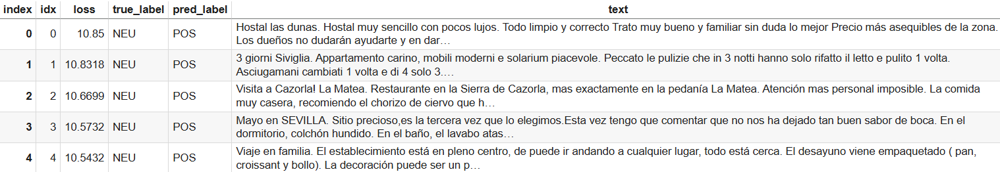

De estos ejemplos, cabe destacar en primer lugar que me parece sorprendente que se haya colado una reseña en italiano (idx 1).

Por otro lado, de los ejemplos que se ven, ocurre lo que ya comentamos en cuadernos anteriores, y es que hay reseñas que, al leerlas, se diría que son positivas. Sin embargo, el etiquetado original del dataset las clasifica como neutras, lo que me hace plantearme que parte de los errores que se atribuyen al modelo, son en realidad errores de etiquetado del dataset. (idx 0 o idx 2, por ejemplo).

Más adelante analizaremos alguno de estos ejemplos con LIME.

# Visualizaciones con LIME

A continuación, vamos a visualizar algunos ejemplos con LIME para comprobar qué terminos empujan o alejan al modelo a la hora de considerar las reseñas negativas, neutras o positivas.

In [ ]:
# Instalar LIME
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=d8948d5c8ecb6c2ab741c060291d6f3546283b828639741822623b63da593b4b
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


In [ ]:
from lime.lime_text import LimeTextExplainer
import torch
import torch.nn.functional as F

explainer = LimeTextExplainer(class_names=["NEG","NEU","POS"])

def predict_proba(texts):
    model1.eval()
    enc = tokenizer1(
        texts,
        padding="max_length",
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)
    with torch.no_grad():
        logits = model1(**enc).logits
    return F.softmax(logits, dim=-1).cpu().numpy()

# Extrae dos ejemplos por clase correctamente clasificada
correct_idxs = {"NEG": [], "NEU": [], "POS": []}
for idx, row in df_test_sorted.iterrows():
    gold = row["gold_label"]
    pred = row["predicted_label"]
    if gold == pred and len(correct_idxs[gold]) < 2:
        correct_idxs[gold].append(idx)
    if all(len(v)==2 for v in correct_idxs.values()):
        break

# Explica cada ejemplo con LIME
for cls, idxs in correct_idxs.items():
    for idx in idxs:
        raw = df_test_sorted.loc[idx, "text_full"]
        print(f"\n--- LIME for correct {cls} example (idx={idx}) ---")
        print(raw[:200] + "…\n")

        # 1) Vacía caché
        torch.cuda.empty_cache()

        # 2) Explicación con pocos samples y features
        exp = explainer.explain_instance(
            raw,
            predict_proba,
            num_features=5,    # mostrar solo 5 palabras/clasificadores
            num_samples=50,    # solo 50 perturbaciones
            top_labels=1
        )
        # 3) Muestra inline
        exp.show_in_notebook(text=True)



--- LIME for correct NEG example (idx=127) ---
No es un 4 estrellas . Hotel ubicado justo a la entrada de Granada, el servicio es normal, pero el hotel no merece ser un 4 estrellas, es más bien un tres estrellas. Lo recomiendo para una muy buena o…




--- LIME for correct NEG example (idx=133) ---
Mal acceso. El hotel tiene unas escaleras para entrar que llevando maleta se hace muy incómoda la entrada.La recepción está en el primer piso,y el ascensor no llega a ese piso.Para subir con maleta ti…




--- LIME for correct NEU example (idx=130) ---
ruidos. Estuve hospedado en este hostal en SEPTIEMBRE 2019. Le hubiera puntuado más, la gente es amable y el hostal y limpieza impecable pero......que no te den las habitaciones de abajo junto al supe…




--- LIME for correct NEU example (idx=131) ---
PENSION CORRECTA CERCA DE LA ESTACIÓN. Pension correcta, buena relacion calidad precio. Muy cerca de la estacion y 10 min andando a la calle Larios. Sin desayuno, pero la cafeteria de la esquina tiene…




--- LIME for correct POS example (idx=128) ---
Buen hotel pero desayuno mejorable. El hotel es magnífico, edificio histórico, buen servicio y buena ubicación. Estuvimos en una habitación superior estéticamente muy agradable, alrededor del claustro…




--- LIME for correct POS example (idx=129) ---
Calidad-precio buena. Hemos estado alojados 5 días en este hotel y yo y mi familia hemos estado muy cómodos. La piscina pequeña pero vamos para hechaste un baño estaba bien y si no pues te vas a la pl…



# Análisis de las visualizaciones

Como en cuadernos anteriores, para facilitar el cotejo del texto de análisis con su correspondiente visualización (y evitar tener que hacer scroll continuamente), acerco la captura de pantalla de las respectivas reseñas.

## **Análisis de la clase NEG**

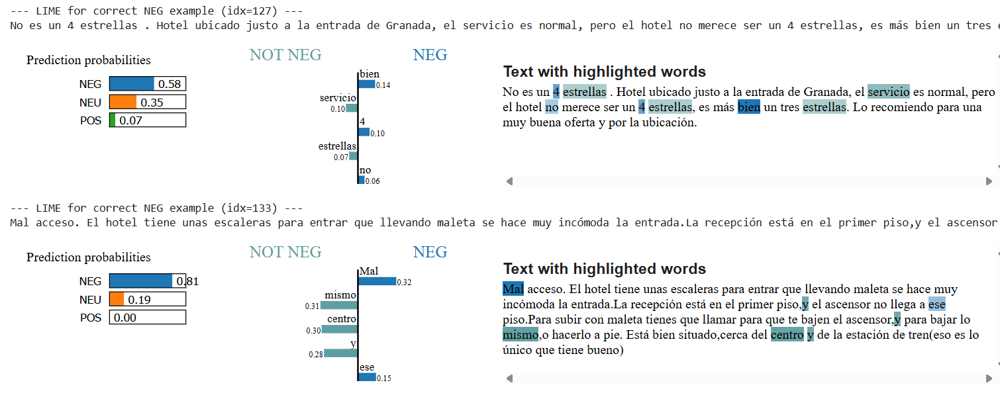

**Nivel de confianza**
En ambos ejemplos el modelo asigna **NEG** con alta certeza (≈0.60–0.80), descartando en gran medida NEU y POS.


### Palabras que acercan a NEG

**Primer ejemplo (idx=127: “No es un 4 estrellas…”)**

* **“no”** y **“4 estrellas”** aparecen como los mayores impulsores de NEG, destacando la crítica directa a la categoría del hotel.
* **“bien”** y **“servicio”** con peso negativo sugieren que, aunque describe aspectos neutros (“servicio”), el contexto sigue siendo desfavorable (“servicio es normal” frente a la expectativa de un 4 estrellas).

**Segundo ejemplo (idx=133: “Mal acceso. El hotel tiene unas escaleras…”)**

* **“Mal”** es el mayor indicador de NEG, reforzado por **“mismo”** y **“ese”**, que se refieren a una mala experiencia recurrente en la entrada.
* **“centro”** y **“y”** aparecen con peso negativo secundario, señalando que, aunque esté céntrico, la incomodidad (“mal acceso”) domina la valoración.



### Palabras que alejan de NEG

* En ninguno de los dos casos LIME muestra fuertes pesos positivos (POS) o neutros (NEU), lo que indica que el texto no contiene indicadores de satisfacción o neutralidad suficientes para contrarrestar la queja.

---

### En general:

Ambos casos ilustran cómo el modelo capta el **tono de insatisfacción explícita**:

1. **Crítica a la categoría** (“No es un 4 estrellas”) se interpreta como decepción general.
2. **Queja logística** (“Mal acceso”, “escaleras incómodas”) refuerza la evaluación negativa.

El modelo pone especial atención en los adverbios y adjetivos de carga negativa (“no”, “mal”) y en los sustantivos concretos que describen la incidencia (“4 estrellas”, “escaleras”), lo cual coincide con nuestra intuición de que esos términos son los más relevantes para expresar enfado.

En conjunto, estas explicaciones LIME confirman que el fine-tuned BERT en español se apoya correctamente en las expresiones de queja directa y en los referentes de servicio para clasificar de forma consistente como NEG.


## **Análisis de la clase NEU**

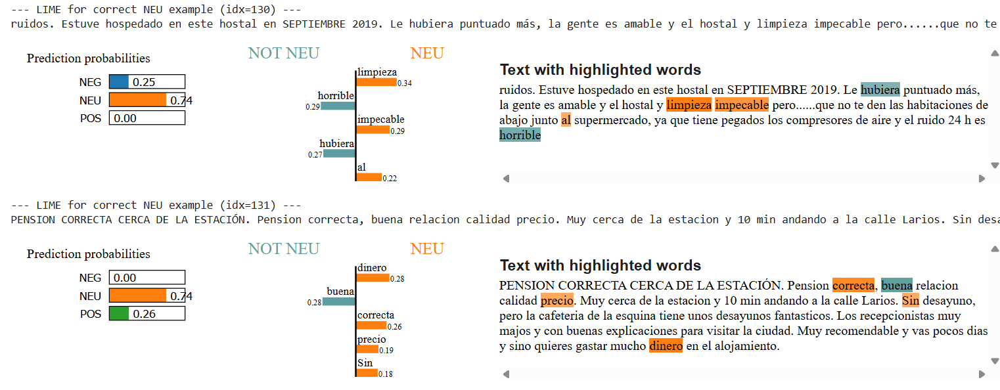

**Nivel de confianza**
En ambos ejemplos el modelo asigna **NEU** con certeza moderada (≈0.74), descartando en gran medida POS y, en uno de los casos, también NEG de forma contundente.


### Palabras que acercan a NEU

**Primer ejemplo (idx=130: “ruidos. Estuve hospedado…”)**

* **“limpieza impecable”** con peso alto impulsa hacia NEU, ya que describe un atributo que posteriormente es contrarrestado con una objeción "pero".
* **“hubiera”** aparece como indicador neutro—expresa una preferencia (“hubiera puntuado más”) sin llegar al elogio directo.

**Segundo ejemplo (idx=131: “PENSION CORRECTA CERCA DE LA ESTACIÓN…”)**

* **“correcta”** y **“precio”** son los principales impulsores de NEU, subrayando una valoración equilibrada (“buena relación calidad-precio”) sin calificaciones extremas.
* **“Sin”** (en “Sin desayuno”) actúa como marcador neutro: informa de un servicio ausente sin enfatizar positividad o negatividad.



### Palabras que alejan de NEU

* **“horrible”** aparece con peso negativo en el primer ejemplo, empujando hacia NEG, pero su influencia queda contrapesada por los términos neutros (“limpieza impecable”).
* **“buena”** y **“dinero”** en el segundo caso tienen ligera connotación positiva, moviendo algo la predicción hacia POS, aunque insuficientemente para cambiar la etiqueta.



### En general

Ambos casos exhiben descripciones **objetivas** de las estancias—mencionan pros (“limpieza impecable”, “buena relación calidad-precio”) y contras (“ruidos”, “sin desayuno”) de forma informativa. El modelo detecta correctamente este **tono informativo** sin inclinación clara hacia la satisfacción o la queja, apoyándose en adjetivos y sustantivos de corte funcional (“correcta”, “precio”, "limpieza") para clasificar como NEU.

Estos ejemplos muestran que a pesar de las dificultades del modelo para reconocer la clase neutra (según los valores observados en classification report) puede, hasta cierto punto, distinguir como neutras valoraciones con descripciones que puedan contener alguna palabra polarizada ("horrible", "impecable").

## **Análisis de la clase POS**


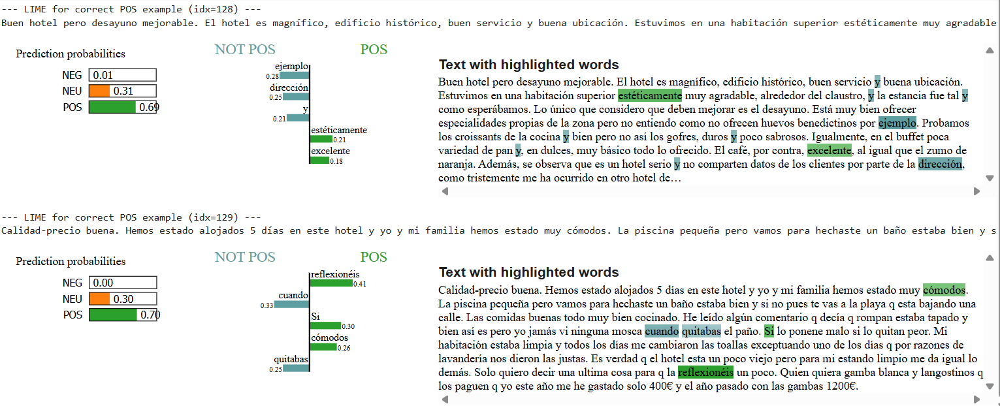

**Nivel de confianza**
En ambos ejemplos el modelo asigna **POS** con certeza sólida (≈0.70), relegando NEG y NEU a probabilidades muy bajas.


### Palabras que acercan a POS

**Primer ejemplo (idx=128: “Buen hotel pero desayuno mejorable…”)**

* **“excelente”** y **“estéticamente”** son los mayores impulsores de POS, destacando atributos muy positivos (“excelente”, “estéticamente agradable”).
* **“ejemplo”** y **“dirección”** también aparecen con peso positivo, sugiriendo que las referencias a “ofrecer por ejemplo” y “dirección” se interpretan en un contexto de recomendaciones favorables.

**Segundo ejemplo (idx=129: “Calidad-precio buena…”)**

* **“cómodos”** y **“reflexión”** impulsan POS, poniendo énfasis en la comodidad de la estancia y en las valoraciones reflexivas positivas.
* **“Sí”** actúa como reforzador afirmativo (“Sí lo ponen”), mientras que **“cuando”** aparece en un giro narrativo positivo.



### Palabras que alejan de POS

* En ninguno de los dos casos LIME muestra grandes pesos para NEG, pero sí un moderado impulso hacia NEU con términos como **“pero”** y **“poco”** (por ejemplo, “desayuno mejorable”, “un poco viejo”), que introducen matices de objeción o reparo.


### En general:

Ambos textos contienen expresiones de **satisfacción** clara:

1. Destacan cualidades positivas (“excelente”, “cómodos”, “estéticamente agradable”) que pesan más que las objeciones menores (“desayuno mejorable”, “poco viejo”).
2. El modelo identifica correctamente estas **palabras connotadas** como señal de opinión favorable y las usa para decantarse por POS.

Con estos ejemplos, vemos que el modelo refinado de BERT en español capta bien los adjetivos y sustantivos positivos, incluso cuando se acompañan de pequeñas críticas, priorizando siempre el tono general de elogio.

No obstante, desde mi punto de vista personal, considero que la primera reseña (idx=128) es más neutra que positiva, y me sorprenden tanto el etiquetado original como la predicción del modelo. Contiene descripciones positivas, pero también aspectos negativos que, a mi juicio, están en igualdad de cantidad y de intensidad en la emoción. Me sorprende que LIME no haya sacado con mayor peso expresiones como "mejorable,"no entiendo como no ofrecen", "no así los gofres (...) duros y poco sabrosos", "poca variedad de pan" o "muy básico todo lo ofrecido". Al leer esta reseña por primera vez, lo primero que pensé es que era neutra y me sorprendió comprobar que estaba etiquetada como positiva tanto por en el dataset, como por el propio modelo.


# Visualización con LIME del caso más problemático (error de etiquetado con mayor pérdida)

In [ ]:
from lime.lime_text import LimeTextExplainer

# 1) Si necesitas preprocesar el texto (opcional):
#    En nuestro caso el tokenizer de HuggingFace ya hace el trabajo,
#    así que omitimos spaCy y preprocess.

# 2) Define predict_proba en el estilo de HuggingFace
import torch
import torch.nn.functional as F

def predict_proba(texts):
    """
    texts: lista de strings sin procesar
    Devuelve una matriz [len(texts), n_labels] de probabilidades.
    """
    model1.eval()
    # Tokenizamos y retornamos tensores PyTorch en GPU
    enc = tokenizer1(
        texts,
        padding="max_length",
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)
    with torch.no_grad():
        logits = model1(**enc).logits
    return F.softmax(logits, dim=-1).cpu().numpy()

# 3) Instancia LIME
explainer = LimeTextExplainer(class_names=["NEG","NEU","POS"])

# 4) Explica el caso más problemático (índice en df_test_sorted)
idx = df_test_sorted.index[0]   # índice 1646 en tu ejemplo real
raw = df_test_sorted.loc[idx, "text_full"]
true_lbl = df_test_sorted.loc[idx, "gold_label"]
pred_lbl = df_test_sorted.loc[idx, "predicted_label"]

print(f"Texto idx={idx} (True: {true_lbl}  Pred: {pred_lbl}):\n{raw}\n")

# 5) Llama a LIME
exp = explainer.explain_instance(
    raw,
    predict_proba,
    num_features=10,
    top_labels=1,      # enfocarnos en la etiqueta más probable
    num_samples=200    # ajusta si la GPU se satura
)

# 6) Mostrar inline el widget completo (texto + barras)
exp.show_in_notebook(text=True)


Texto idx=0 (True: NEU  Pred: POS):
Hostal las dunas. Hostal muy sencillo con pocos lujos.  Todo limpio y correcto  Trato muy bueno y familiar sin duda lo mejor  Precio más asequibles de la zona.  Los dueños no dudarán ayudarte y en darte el mejor servicio posible.



1. **Palabras que empujan hacia POS**

   * **“duda” / “dudarán”** (peso ≈ 0.14)
   * **“con”** (0.10)
   * **“familiar”** (0.08)
   * **“bueno”** (0.07)
   * **“asequibles”** (0.07)
   * **“ayudarte”** (0.07)

   Estos términos resaltan la comodidad, la amabilidad y la asequibilidad, atributos claramente positivos.

2. **Palabras que alejan de POS**

   * No aparecen barras rojas de tamaño significativo: LIME no detecta en este texto ningún token con carga negativa capaz de contrapesar los muchos indicadores positivos, si bien, la expresión "muy sencillo con pocos lujos" debería haber dado una pista.



## ¿Por qué falla el modelo?

* **Perfil neutro vs. positivo**
  Aunque el mensaje contiene valoraciones objetivas (“muy sencillo”, “pocos lujos”), su tono global es más informativo que entusiasta: describe características del hostal sin un entusiasmo desbordado ni calificativos extremos (“magnífico”, “excelente”).
* **Ausencia de marcadores negativos**
  No hay críticas ni negatividad; para el modelo, la concatenación de “muy bueno”, “familiar”, “asequibles” pesa más que su neutralidad efectiva.
* **Distinción sutil entre NEU/POS**
  En NEU caben opiniones descriptivas balanceadas (“correcto”, “familiar”), que aquí se interpretan como positivas. El modelo no distingue entre “descripción favorable moderada” (NEU) y “elogio claro” (POS).



## Conclusión

* **Para LIME**, cualquier mención de “bueno”, “familiar” o “ayudarte” es positiva.
* **Para un humano**, el texto simplemente informa de un servicio correcto y amable, más cercano al neutro.

**Posible mejora**:

* Incluir ejemplos de satisfacción moderada en el conjunto de `dev` para que el modelo aprenda a no elevar calificaciones descriptivas a “positivo” pleno.
* Ajustar el umbral de confianza (por ejemplo, exigir POS > 0.8) para reclasificar ciertos casos a NEU.


In [ ]:
from lime.lime_text import LimeTextExplainer

# 1) Si necesitas preprocesar el texto (opcional):
#    En nuestro caso el tokenizer de HuggingFace ya hace el trabajo,
#    así que omitimos spaCy y preprocess.

# 2) Define predict_proba en el estilo de HuggingFace
import torch
import torch.nn.functional as F

def predict_proba(texts):
    """
    texts: lista de strings sin procesar
    Devuelve una matriz [len(texts), n_labels] de probabilidades.
    """
    model1.eval()
    # Tokenizamos y retornamos tensores PyTorch en GPU
    enc = tokenizer1(
        texts,
        padding="max_length",
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)
    with torch.no_grad():
        logits = model1(**enc).logits
    return F.softmax(logits, dim=-1).cpu().numpy()

# 3) Instancia LIME
explainer = LimeTextExplainer(class_names=["NEG","NEU","POS"])

# 4) Explica el caso más problemático (índice en df_test_sorted)
idx = df_test_sorted.index[3]
raw = df_test_sorted.loc[idx, "text_full"]
true_lbl = df_test_sorted.loc[idx, "gold_label"]
pred_lbl = df_test_sorted.loc[idx, "predicted_label"]

print(f"Texto idx={idx} (True: {true_lbl}  Pred: {pred_lbl}):\n{raw}\n")

# 5) Llama a LIME
exp = explainer.explain_instance(
    raw,
    predict_proba,
    num_features=10,
    top_labels=1,      # enfocarnos en la etiqueta más probable
    num_samples=200    # ajusta si la GPU se satura
)

# 6) Mostrar inline el widget completo (texto + barras)
exp.show_in_notebook(text=True)


Texto idx=3 (True: NEU  Pred: POS):
Mayo en SEVILLA. Sitio precioso,es la tercera vez que lo elegimos.Esta vez tengo que comentar que no nos ha dejado tan buen sabor de boca. En el dormitorio, colchón hundido. En el baño, el lavabo atascado. En el desayuno de cortesía, podrían prestar más atención al lavado de la vajilla. Ubicación perfecta. Un saludo.



* **Pérdida alta**: Probabilidad POS = 1.00 (muy seguro), para una reseña con etiqueta NEU como referencia.


1. **Palabras que empujan hacia POS**

   * **“perfecta”** (0.40) y **“precioso”** (0.31): calificativos muy positivos sobre el sitio y la ubicación.
   * **“saludo”** (0.15): tono amable de cierre (“Un saludo”).
   * **“colchón”** (0.09) y **“tengo”** (0.06): aparecen en contexto positivo (“tengo que comentar…” interpretado erróneamente como positivo).

3. **Palabras que alejan de POS**

   * **“atascado”** (−0.14) y **“hundido”** (−0.12): indican problemas (lavabo obstruido, colchón deteriorado) que deberían empujar más hacia NEU o NEG, pero sus pesos negativos no bastan frente a los calificativos de bastante peso como “precioso” y “perfecta”.
   * **“baño”** (−0.11) marca el contexto del fallo sin peso positivo.

4. **Resaltado en el texto**

   * LIME marca en diferentes colores, por un lado “precioso”, “perfecta”, “saludo” y, por otro, “atascado”, “hundido”, mostrando el "forcejeo" entre elogio y crítica.



## Conclusión

* **Tono mixto**: por un lado, elogios entusiastas (“sitio precioso”, “ubicación perfecta”); por otro, quejas concretas (“colchón hundido”, “lavabo atascado”).
* **Desequilibrio**: los calificativos positivos pesan más que las reclamaciones técnicas, llevando al modelo a elegir POS con total confianza.
* **Zona gris**: un humano clasificaría esto probablemente como **NEU** (mezcla de pro y contra), o incluso como **NEU–NEG** debido a los fallos, pero el modelo privilegia las palabras de tono claramente positivo.



## Posibilidades de mejora

* **Rebalancear ejemplos NEU** con opiniones mixtas en los datos de entrenamiento para que el modelo aprenda a moderar la presencia de calificativos extremos cuando hay críticas concurrentes.
* **Ajustar umbrales**: requerir un umbral más alto de POS (> 0.9) y si hay quejas detectadas bajar a NEU.
* **Reglas heurísticas**: detectar palabras de fallos (“atascado”, “hundido”) con peso especial que contrarresten automáticamente grandes elogios.


# Conclusiones generales de aprendizaje transferido

No son muy diferentes a las descritas en anteriores cuadernos y en el apartado de conclusiones generales de todo el proyecto, ya entro en detalles.

Sólo destacar que con el entrenamiento de este modelo y sus posteriores análisis cuantitativos y cualitativos, se confirma lo que ya se veía en otros cuadernos: *grosso modo*, que la limitada muestra de la clase neutra (en comparación con la clase POS, por ejemplo) y el erróneo etiquetado que a veces he detectado en el corpus original destacan (a mi juicio) como principales factores de los errores del modelo.





# **CONCLUSIONES DEL PROYECTO COMPLETO DE ANÁLISIS DE SENTIMIENTOS (LOS 4 MODELOS)**

Aunque en cada cuaderno he ido comentando tanto desde el enfoque cuantitativo como cualitativo, en este apartado cito aquellas conclusiones a modo de resumen.

## 1. Resumen cuantitativo y comparativa de enfoques

| Enfoque                               |  Test Acc  |   F1-NEG   |   F1-NEU   |   F1-POS   |  Macro-F1  | Weighted-F1 | Notas clave                                                                  |
| :------------------------------------ | :--------: | :--------: | :--------: | :--------: | :--------: | :---------: | :--------------------------------------------------------------------------- |
| **Lexicón sin reglas**                |    0.613   |    0.257   |    0.029   |    0.695   |    0.309   |    0.569    | Alta accuracy "ilusoria"; casi no detecta NEU/NEG.                             |
| **Lexicón con reglas heurísticas**    |    0.546   |    0.403   |    0.035   |    0.758   |    0.379   |    0.621    | Mejora macro-F1 y recall NEG (0.93) vs. sin reglas; NEU sigue muy débil.     |
| **LogReg (solo n-gramas)**            | 0.9186 | 0.8981 | 0.6633 | 0.9595 | 0.8403 |  0.9133 | Mejor ML tradicinoal; detecta bien POS/NEG; NEU mejora levemente (F1≈0.66, recall≈0.57).   |
| **LogReg (n-gramas + léxico)**        |   0.8608   |   0.8203   |   0.3108   |   0.9257   |   0.6856   |    0.8331   | El lexicón empeora neutralidad (F1\_NEU cae a 0.31) y accuracy. |
| **Deep Learning (RNN + Pooling emb300_u128_ep20_p10)**     |   0.8916   |   0.8403   |   0.6303   |   0.9505   |   0.8063   |      –      | Pooling esencial para generalizar vs. RNN simple.                            |
| **BERT refinado (3 ep, 2e-5,0.01)** | **0.9307** |    0.910   |    0.731   |    0.970   | **0.8693** |      –      | Mejoría general y de clase NEU en particular (F1\_NEU=**0.73**, recall=**0.86**).             |




**Ganador cuantitativo:**

El modelo de aprendizaje transferido en su versión refinada (Experimento 1) es el más robusto (Macro-F1 ≈ 0.87), seguido muy de cerca por LogReg con n-gramas (Macro-F1 ≈ 0.84) y RNN+Pooling (Macro-F1 ≈ 0.81).



## 2. Análisis cualitativo global

Resumen de lo ya comentado en los cuadernos anteriores:

* **Fortalezas comunes**

  * Captura con precisión los **superlativos** y **adjetivos extremos** (“excelente”, “perfecta”, “magnífico”) para POS.
  * Reconoce las quejas **explícitas** (“horrible”, “atascado”, “colchón hundido”) para NEG.

* **Debilidades recurrentes**

  * Da excesivo peso a los términos positivos moderados, lo que le lleva a identificar muchas reseñas neutras como positivas.
  * Penaliza adversativos de forma insuficiente (“pero”, “aunque”), por lo que comete errores al clasificar reseñas que combinan aspectos positivos con negativos.
  * NEU sigue siendo la clase más difícil: recall y f1 muy bajos en casi todos los enfoques, si bien, el modelo refinado de BERT es con diferencia el que mejor trata esta clase: Recall(NEU): 0.86 y F1-score(NEU): 0.73









## 3. Predicciones de cada modelo, obtenidas del csv

Mostraremos una pequeña muestra de 20 reseñas, particularmente aquellas reseñas en las que haya habido más errores por parte de los modelos.

In [ ]:
import pandas as pd
from IPython.display import display

# 1) Define las rutas
path_full = '/content/drive/MyDrive/0.Apuntes PLN/predicciones_modelos_completo.csv'

# 2) Carga los CSV en dos variables distintas
dffull = pd.read_csv(path_full)

# 3) Define la lista de columnas de predicción
#    ajusta los nombres si tus columnas son distintas
pred_cols = ['Pred. lexicón', 'Pred.RegLog', 'Pred.Deep', 'Pred.Trf']

# 4) Calcula el número de errores por fila
#    compara cada columna de predicción con la real
for df in (df100, dffull):
    df['error_count'] = df[pred_cols].ne(df['Real'], axis=0).sum(axis=1)

# 5) Extrae las top-20 filas con más errores y muestra
print("🔹 Top 20 casos con más errores — predicciones_modelos_completo.csv")
topfull = dffull.sort_values('error_count', ascending=False).head(20).reset_index(drop=True)
display(topfull)


🔹 Top 20 casos con más errores — predicciones_modelos_completo.csv


,text,Real,Pred. lexicón,Pred.RegLog,Pred.Deep,Pred.Trf,error_count
0,"Mejorable. Personal agradable, servicio deja q...",NEU,NEG,POS,NEG,NEG,4
1,Bueno auberge. Muy bonita y limpia auberge no ...,NEU,NEG,POS,POS,POS,4
2,CALIDAD PRECIO AJUSTADO. Comentario basado en ...,NEU,POS,POS,POS,POS,4
3,AGRADABLE ESTANCIA EN SEVILLA. Hostel muy bien...,NEU,POS,POS,POS,POS,4
4,"Buen hotel, servicio decepcionante. Me hospedé...",NEU,NEG,NEG,POS,NEG,4
5,Cuidado que no te den una habitacion en planta...,NEU,NEG,POS,POS,NEG,4
6,Buena relacion calidad/precio. Amabilidad del ...,NEU,POS,POS,POS,POS,4
7,"Bien . El hotel cuenta con buena ubicación, es...",POS,NEU,NEG,NEG,NEU,4
8,MALAFOLLÀS. vaya malafollá que tiene la joven ...,NEU,NEG,NEG,NEG,NEG,4
9,buen precio. estuve alojada en el hostal en ag...,NEU,POS,POS,POS,POS,4


Por si la tabla interactiva no se despliega, incluyo captura de pantalla de algunas de las muestras con su texto completo.
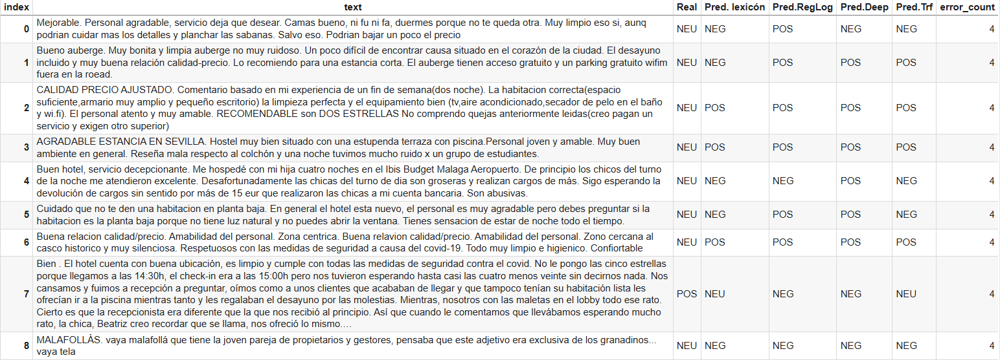

Como era de esperar, todas las reseñas de esta pequeña muestra corresponden a reseñas originalmente neutras en el dataset, pero que los modelos han errado al calificar. En algunos ejemplos coinciden las predicciones de todos los modelos (por ej., idx 2, 3, 6 u 8).



## 4. Valoración del corpus
En conjunto, tras todos los experimentos realizados, los resultados que se han ido obteniendo sugieren que el dataset sí es útil para entrenar modelos, aunque presenta ciertas limitaciones estructurales:


* **Desequilibrio de clases**:
  La clase **POS** domina sobradamente sobre **NEU** y **NEG** (POS ≈ 73 %, NEU ≈ 12 %, NEG ≈ 15 %), lo que condiciona al modelo a favorecer predicciones positivas incluso en textos de tono más moderado o negativo.

* **Supuesto ruido en NEU**:
  Muchas reseñas etiquetadas como neutras emplean un lenguaje claramente positivo (“limpieza impecable”) o negativo (“colchón hundido”).

* **Ruido de idiomas**: Se han encontrado algunas reseñas en italiano, lo que puede haber influido en el entrenamiento y en los valores que se han obtenido en la evaluación. Convendría limpiar el dataset y eliminarlas.

* **Calidad del etiquetado**:
  Muchas reseñas originalmente etiquetadas como POS o NEG (ejemplos ya comentados en los cuadernos), son en realidad neutras o, al menos, bajo mi punto de vista, lo cual dificulta a la hora de definir la frontera entre NEU y las otras dos clases. Aunque en general el etiquetado del dataset es bastante fino, sería necesaria una revisión manual para verificar que las etiquetas calificadas como NEU en el dataset, efectivamente lo sean.



#### Fortalezas del dataset

* **Volumen y diversidad** suficiente para que BERT alcance \~93 % de accuracy y Macro-F1≈0.87.
* **Se capturan bien** las clases «POS» y «NEG» incluso con modelos tradicionales (LogReg alcanza F1≈0.90/0.96 en estas categorías).
* **Válido para modelos complejos** (RNN+pooling, Transformers) mejoran sustancialmente la detección de la clase «NEU» (hasta F1≈0.73 con BERT).



### Conclusión y posibilidades de mejora

El dataset es lo bastante grande y variado como para sacar partido a modelos más avanzados (transfer learning, RNN con embeddings). Sin embargo, para tareas más “ligeras” (lexicón puro, reglas heurísticas) se hacen más patentes sus limitaciones (sobre todo en la detección de la neutralidad).

Para mejorar el dataset, puede ser útil:

* Reequilibrar (o aportar más muestras para) la clase NEU.
* Hacer limpieza lingüística para asegurar que sólo haya reseñas en español.
* Revisar el etiquetado para corregir aquellas etiquetas que no concuerdan realmente con el verdadero sentimiento de la reseña (ejemplos que ya hemos visto y comentado en cuadernos anteriores).
* Enriquecer el lexicón con términos y expresiones propias de las reseñas, lo que sería especialmente provechoso para los métodos basados en reglas.



# **5.REFLEXIONES FINALES**


### **¿Macro-f1 es realmente el único factor a tener en cuenta a la hora de decidir cual es el modelo óptimo?**

Aparte de las métricas, cabe preguntarse qué modelo responde mejor según la tarea concreta o el objetivo que se pretenda alcanzar. No sólo importa la métrica más alta, sino también el coste en tiempo y recursos.
No es lo mismo un modelo con lexicón, que para este proyecto y dataset tardó apenas unos minutos en entrenarse, frente al modelo de aprendizaje transferido que (aunque obtuvo la métrica más alta) fue el más exigente en recursos y en tiempo (más de 30 minutos)


Por ejemplo:

* **Cuándo es óptimo el modelo de lexicón con reglas**: Pese a la baja puntuación que obtuvo, este enfoque sería válido para obtener una primera impresión rápida del sentimiento sin complicarnos con instalaciones o infraestructuras complejas. Con solo unas pocas líneas de Python y un diccionario de palabras, puedes detectar opiniones claramente positivas o negativas, por lo que es perfecto para análisis básicos, proyectos exploratorios o entornos con recursos muy limitados.

* **Cuándo es óptimo el modelo de regresión logística basada en n-gramas**: Este modelo ofrece un salto importante en calidad al tiempo que se mantiene en un nivel bajo-medio de consumo de recursos; gracias a su rapidez de inferencia y su simplicidad, resulta perfecta para integrar en servicios web o APIs de producción donde la latencia debe ser mínima, por ejemplo para monitorizar reseñas en tiempo real o alimentar dashboards de satisfacción de usuarios.

* **Cuándo es óptimo el modelo RNN con pooling de embeddings**: Exige algo más de potencia que la regresión logística, pero a cambio captura mejor el contexto y el orden de las palabras. Esto lo convierte en una buena elección para proyectos intermedios en los que ya se disponga de vectores de palabra preentrenados (por ejemplo, al trabajar con dominios específicos como reseñas médicas o de productos técnicos) y se quiera profundizar en matices de estilo o intencionalidad que van más allá de la frecuencia de n-gramas.

* **Cuándo es óptimo el modelo BERT refinado**: Fue el modelo que mayor rendimiento obtuvo de todos nuestros experimentos, pero necesita una GPU o un entorno con mayor capacidad de cálculo. Su alta precisión y su mejor manejo de la clase neutra lo hacen la opción óptima para escenarios de alto valor, como análisis de opinión de clientes en empresas grandes, detección de tono en contextos legales o financieros, o cualquier caso de uso en el que el coste de un error sea elevado y se justifique el tiempo y la inversión en recursos.


### **Aprendizajes**

Con este "viaje" por los cuatro enfoques (desde el modelo de lexicón, más básico los Transformers) no solo he podido comparar las diferencias cuantitativas y cualitativas de las diversas estrategias de análisis de sentimiento, sino que también he podido apreciar cómo cada modelo tiene sus propias necesidades de preparación del entorno y de preprocesamiento lingúístico para cada caso. Y, por supuesto, queda clara la importancia de partir de un corpus bien nutrido para poder llevar todo lo anterior a cabo con éxito.

Por otro lado, en cuanto a la experiencia de programación, como tal, este proyecto también ha sido interesante para conocer la clase de problemas que se presentan en esta clase de tareas: desconexión del entorno, pérdida de GPU, periodos de entrenamiento demasiado prolongados que impiden terminar una tarea en el momento en que uno se lo proporne... Son pequeños tropiezos que revelan la importancia de ir guardando los modelos una vez entrenados (así como los parámetros previos y la configuración general del entorno), para poder arrancar desde un punto intermedio en lugar de tener que ejecutar el cuaderno desde el principio una y otra vez, por cada inicio de sesión.

En definitiva, ha sido un proyecto completo e intenso con el que he podido asentar los procedimientos y los pasos que son necesarios para entrenar modelos. También me ha dado mucha claridad en cuanto a qué métricas se deben tener en cuenta a la hora de valorar un modelo u otro, y qué clase de visualizaciones son necesarias para "bajar a tierra" los números y así poder analizar lingüísticamente el funcionamiento del modelo, lo cual, como lingüísta, me parece la parte más interesante.


Los resultados de este proyecto me inspiran un paso más:  sabiendo que en nuestros experimentos el modelo de lexicón ha sido el modelo de peor rendimiento (aunque es el más ligero) y BERT refinado el mejor (aunque el más exigente en recursos), y sabiendo que el corpus en el que nos hemos basado es de calidad, **me pregunto si es posible tomar dicho corpus + el modelo refinado, y utilizarlo para actualizar y mejorar el lexicón en español que ya tenemos**. De este modo, conseguiríamos un modelo de lexicón que siga siendo ligero y rápido, pero con un salto notable en precisión.

Sería un experimento curioso para combinar la eficiencia de los enfoques basados en reglas con la potencia de los Transformers.
